In [11]:
import sys
!{sys.executable} -m pip install scikit-learn

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
 

data = pd.read_csv("/Users/shivam/Downloads/seeds_data.csv")
y_true = data["Class"].values              # only used at the very end
X = data.drop(columns=["Class"]).values

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [13]:
def kmeans(X, k):
    np.random.seed(0)
    # start with k random points as the centres
    centers = X[np.random.choice(len(X), k, replace=False)]
 
    for step in range(100):
        
        labels = np.zeros(len(X), dtype=int)
        for i in range(len(X)):
            dist = np.sqrt(((centers - X[i]) ** 2).sum(axis=1))
            labels[i] = dist.argmin()
 
        
        new_centers = np.zeros_like(centers)
        for j in range(k):
            new_centers[j] = X[labels == j].mean(axis=0)
 
        #  stop if the centres did not move
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
 
    # inertia = how far the points are from their centres (smaller = tighter)
    inertia = 0
    for i in range(len(X)):
        inertia += ((X[i] - centers[labels[i]]) ** 2).sum()
 
    return labels, centers, inertia

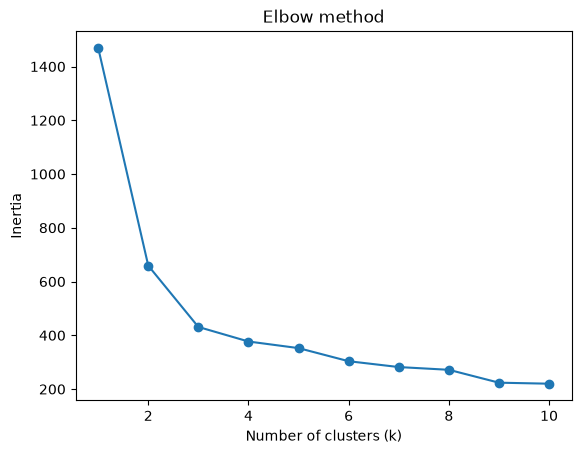

In [14]:
# Elbow method: try k = 1 to 10 and plot the inertia
inertias = []
for k in range(1, 11):
    labels, centers, inertia = kmeans(X, k)
    inertias.append(inertia)
 
plt.plot(range(1, 11), inertias, marker="o")
plt.title("Elbow method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()
 

In [15]:
# The line bends at k = 3, so we use 3 clusters
km_labels, km_centers, inertia = kmeans(X, 3)
 
print("K-Means final centres (each row = one cluster, columns = Feature_1 ... Feature_7):")
print(np.round(scaler.inverse_transform(km_centers), 2))

K-Means final centres (each row = one cluster, columns = Feature_1 ... Feature_7):
[[11.84 13.24  0.85  5.23  2.84  4.88  5.12]
 [18.41 16.17  0.88  6.17  3.68  3.63  6.04]
 [14.29 14.26  0.88  5.49  3.24  2.67  5.09]]


In [16]:
def dbscan(X, eps, min_samples):
    n = len(X)
 
    # find the neighbours (points within eps) of every point
    neighbours = []
    for i in range(n):
        dist = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
        neighbours.append(np.where(dist <= eps)[0])
 
    labels = np.full(n, -1)                # -1 means noise
    cluster = 0
 
    for i in range(n):
        # a new cluster can only start from a core point (enough neighbours)
        # which is not already in a cluster
        if labels[i] != -1 or len(neighbours[i]) < min_samples:
            continue
 
        labels[i] = cluster
        todo = [i]
        while len(todo) > 0:
            p = todo.pop()
            if len(neighbours[p]) >= min_samples:     # only core points spread the cluster
                for q in neighbours[p]:
                    if labels[q] == -1:
                        labels[q] = cluster
                        todo.append(q)
        cluster = cluster + 1
 
    return labels

In [17]:
best_score = 0
best_eps = 0
best_min = 0
for min_samples in [5, 8, 11, 14]:
    for eps in [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4]:
        labels = dbscan(X, eps, min_samples)
        keep = labels != -1                            # points that are not noise
        if len(np.unique(labels[keep])) < 2:           # need at least 2 clusters
            continue
        score = silhouette_score(X[keep], labels[keep]) * keep.mean()
        if score > best_score:
            best_score = score
            best_eps = eps
            best_min = min_samples
 
print("\nBest eps =", best_eps, " Best min_samples =", best_min)
 
db_labels = dbscan(X, best_eps, best_min)
noise = db_labels == -1
print("DBSCAN clusters formed:", len(np.unique(db_labels[~noise])))
print("DBSCAN noise points:", noise.sum())
 


Best eps = 1.1  Best min_samples = 11
DBSCAN clusters formed: 2
DBSCAN noise points: 23


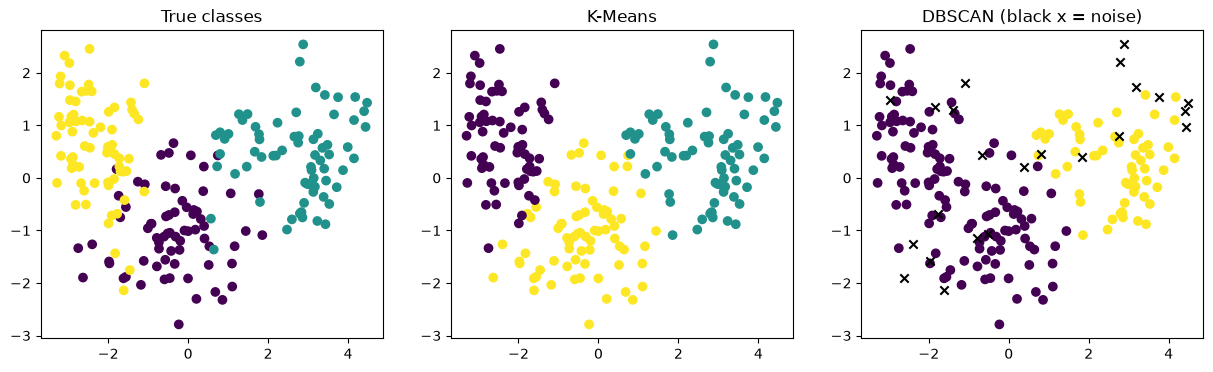

In [18]:
pca_data = PCA(n_components=2).fit_transform(X)
 
plt.figure(figsize=(15, 4))
 
plt.subplot(1, 3, 1)
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=y_true)
plt.title("True classes")
 
plt.subplot(1, 3, 2)
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=km_labels)
plt.title("K-Means")
 
plt.subplot(1, 3, 3)
plt.scatter(pca_data[~noise, 0], pca_data[~noise, 1], c=db_labels[~noise])   # normal points
plt.scatter(pca_data[noise, 0], pca_data[noise, 1], c="black", marker="x")   # noise = black x
plt.title("DBSCAN (black x = noise)")
 
plt.show()

In [19]:
print("\nK-Means clusters vs true classes:")
print(pd.crosstab(y_true, km_labels))
 
print("\nDBSCAN clusters vs true classes (-1 = noise):")
print(pd.crosstab(y_true, db_labels))
 
print("\nAdjusted Rand Index (1 = perfect match, 0 = random)")
print("K-Means:", round(adjusted_rand_score(y_true, km_labels), 3))
print("DBSCAN :", round(adjusted_rand_score(y_true, db_labels), 3))


K-Means clusters vs true classes:
col_0   0   1   2
row_0            
1       3   2  65
2       0  67   3
3      65   0   5

DBSCAN clusters vs true classes (-1 = noise):
col_0  -1   0   1
row_0            
1       7  60   3
2      10   3  57
3       6  64   0

Adjusted Rand Index (1 = perfect match, 0 = random)
K-Means: 0.823
DBSCAN : 0.406
